In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, RobustScaler

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Dense, Dropout, BatchNormalization

In [2]:
df = pd.read_csv('heart.csv')
df.columns = df.columns.str.strip()

df

,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
0,40,M,ATA,140,289,0,Normal,172,N,0.0,Up,0
1,49,F,NAP,160,180,0,Normal,156,N,1.0,Flat,1
2,37,M,ATA,130,283,0,ST,98,N,0.0,Up,0
3,48,F,ASY,138,214,0,Normal,108,Y,1.5,Flat,1
4,54,M,NAP,150,195,0,Normal,122,N,0.0,Up,0
...,...,...,...,...,...,...,...,...,...,...,...,...
913,45,M,TA,110,264,0,Normal,132,N,1.2,Flat,1
914,68,M,ASY,144,193,1,Normal,141,N,3.4,Flat,1
915,57,M,ASY,130,131,0,Normal,115,Y,1.2,Flat,1
916,57,F,ATA,130,236,0,LVH,174,N,0.0,Flat,1


#### Data Overview & Cleaning

In [3]:
def describe_data(df):
    print(f'Dateset Shape: {df.shape}')
    print('='*50)
    df.info()
    return describe_data
describe_data(df)

Dateset Shape: (918, 12)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 918 entries, 0 to 917
Data columns (total 12 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Age             918 non-null    int64  
 1   Sex             918 non-null    object 
 2   ChestPainType   918 non-null    object 
 3   RestingBP       918 non-null    int64  
 4   Cholesterol     918 non-null    int64  
 5   FastingBS       918 non-null    int64  
 6   RestingECG      918 non-null    object 
 7   MaxHR           918 non-null    int64  
 8   ExerciseAngina  918 non-null    object 
 9   Oldpeak         918 non-null    float64
 10  ST_Slope        918 non-null    object 
 11  HeartDisease    918 non-null    int64  
dtypes: float64(1), int64(6), object(5)
memory usage: 86.2+ KB


<function __main__.describe_data(df)>

In [4]:
df.describe()

,Age,RestingBP,Cholesterol,FastingBS,MaxHR,Oldpeak,HeartDisease
count,918.000000,918.000000,918.000000,918.000000,918.000000,918.000000,918.000000
mean,53.510893,132.396514,198.799564,0.233115,136.809368,0.887364,0.553377
std,9.432617,18.514154,109.384145,0.423046,25.460334,1.066570,0.497414
min,28.000000,0.000000,0.000000,0.000000,60.000000,-2.600000,0.000000
25%,47.000000,120.000000,173.250000,0.000000,120.000000,0.000000,0.000000
50%,54.000000,130.000000,223.000000,0.000000,138.000000,0.600000,1.000000
75%,60.000000,140.000000,267.000000,0.000000,156.000000,1.500000,1.000000
max,77.000000,200.000000,603.000000,1.000000,202.000000,6.200000,1.000000


In [5]:
def data_issue(df):
    print(f'Total duplicated values: {df.duplicated().sum()}')
    print('='*50)
    print('Null Values:')
    print(df.isnull().sum())
    return

data_issue(df)

Total duplicated values: 0
Null Values:
Age               0
Sex               0
ChestPainType     0
RestingBP         0
Cholesterol       0
FastingBS         0
RestingECG        0
MaxHR             0
ExerciseAngina    0
Oldpeak           0
ST_Slope          0
HeartDisease      0
dtype: int64


#### Data Visualization

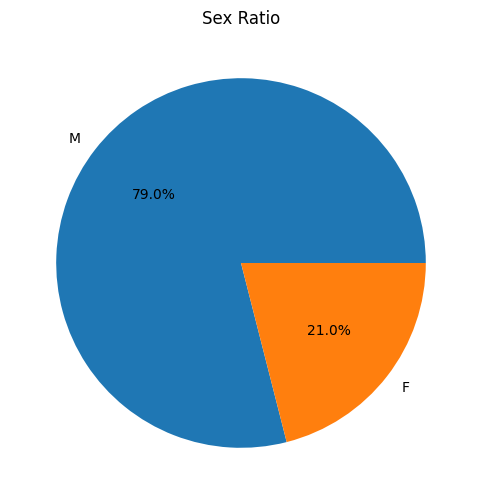

In [6]:
sex = df['Sex'].value_counts()

plt.figure(figsize=(6,6))
plt.pie(sex, 
        labels = sex.index,
        autopct='%1.1f%%'
)
plt.title('Sex Ratio')
plt.show()

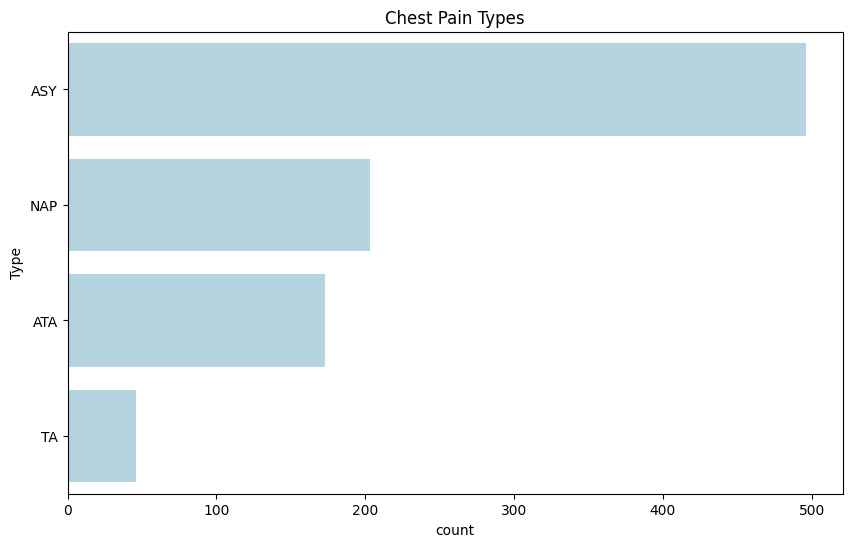

In [7]:
plt.figure(figsize = (10,6))
sns.countplot(
    y='ChestPainType',
    data=df,
    color='lightblue',
    order=df['ChestPainType'].value_counts().index 
)
plt.title('Chest Pain Types')
plt.ylabel('Type')
plt.show()

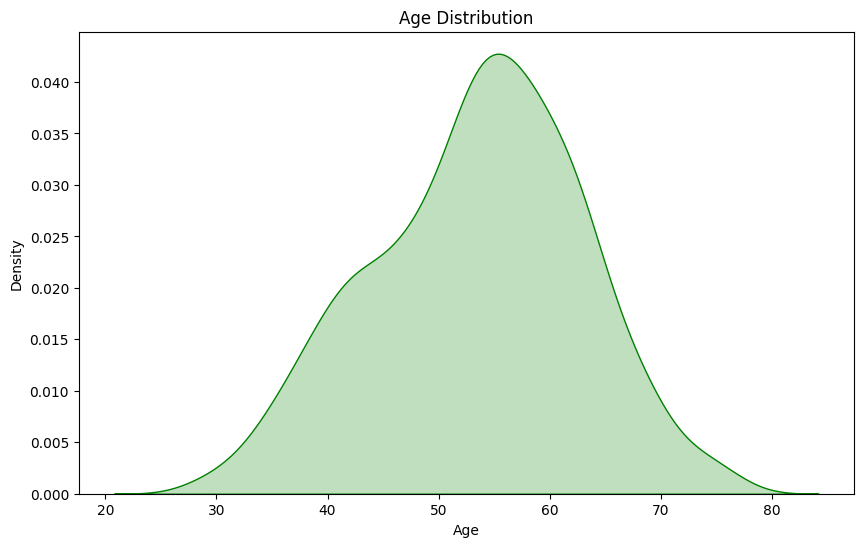

In [8]:
plt.figure(figsize=(10,6))
sns.kdeplot(df['Age'], fill=True, color='green')
plt.title('Age Distribution')
plt.xlabel('Age')
plt.ylabel('Density')
plt.show()

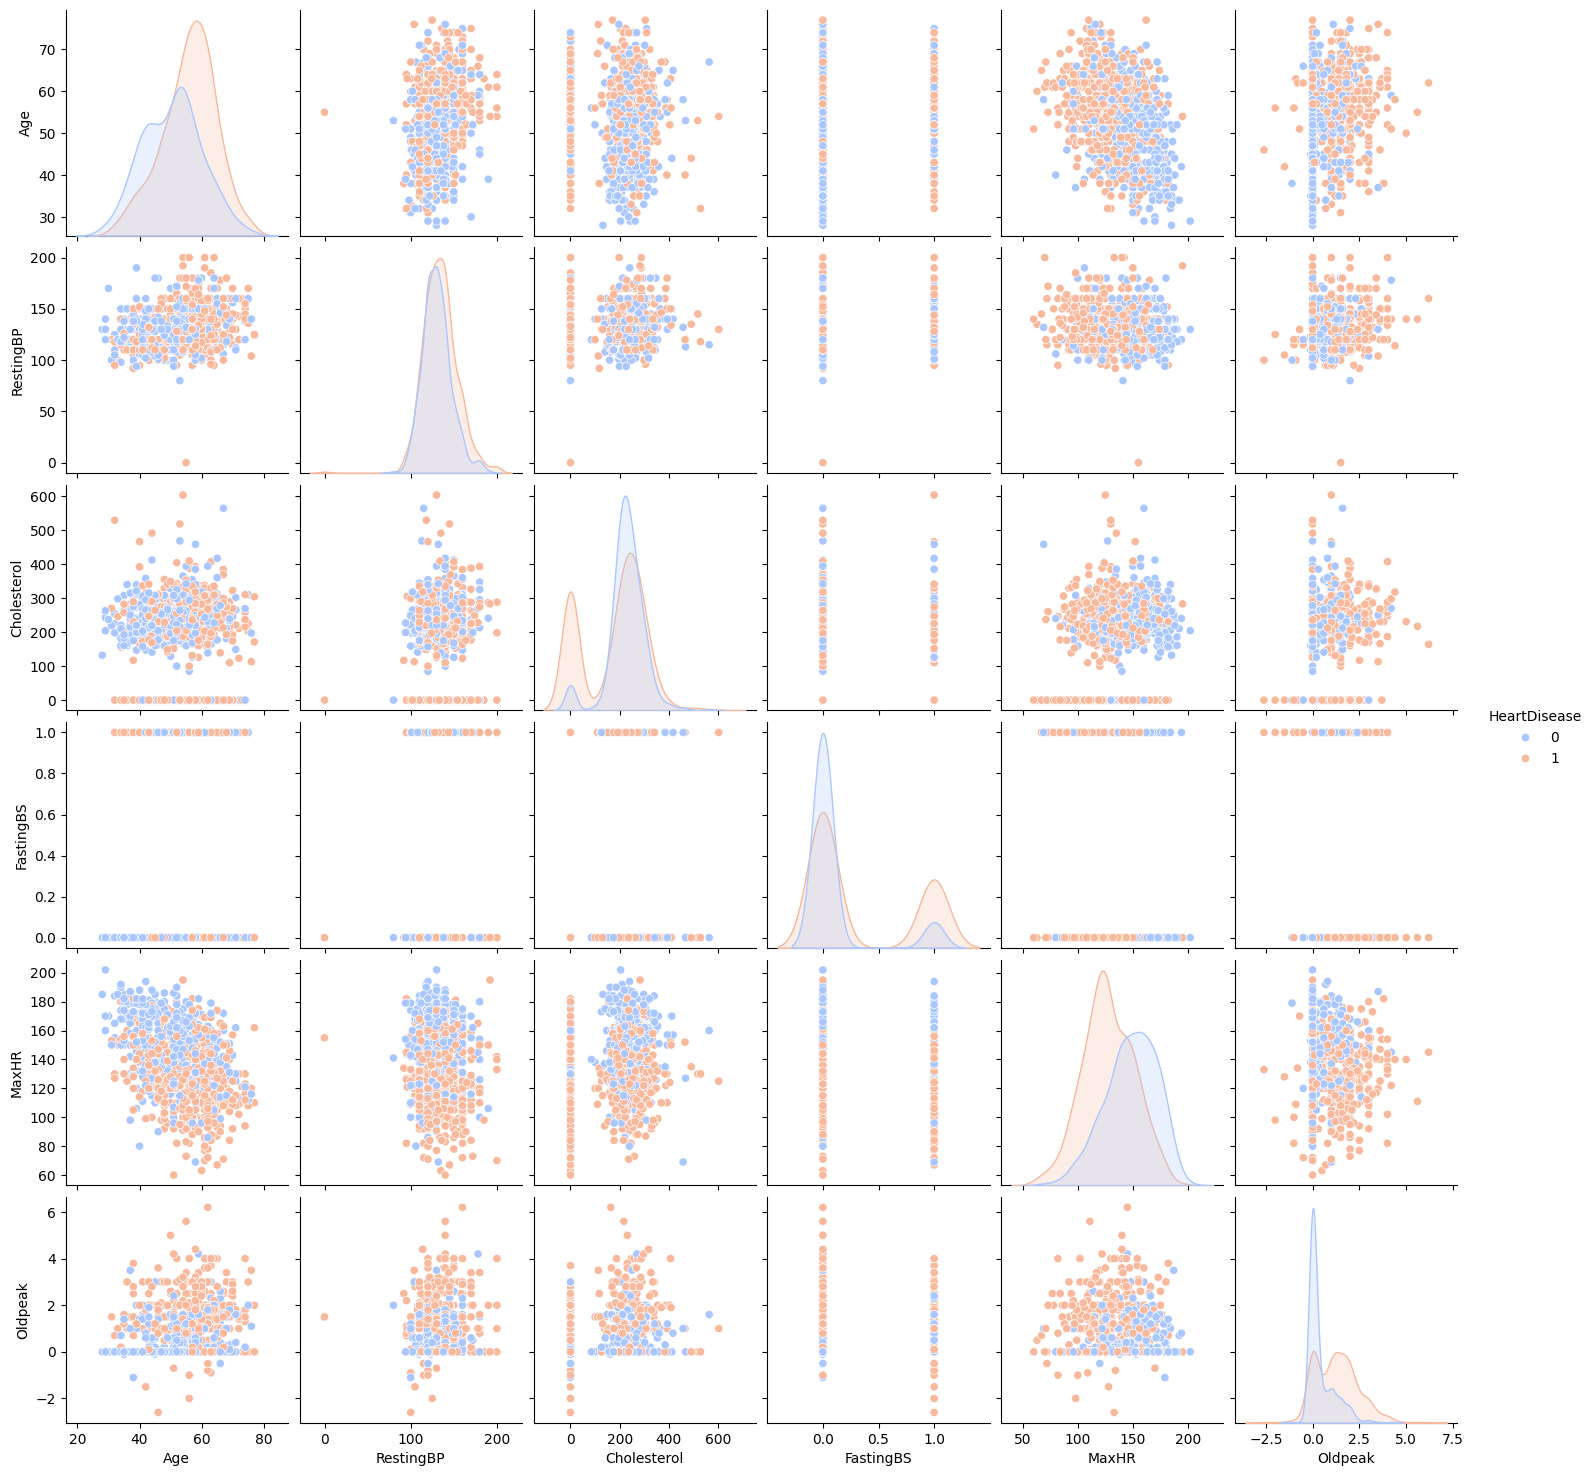

In [9]:
sns.pairplot(df, hue="HeartDisease", palette="coolwarm")
plt.show()

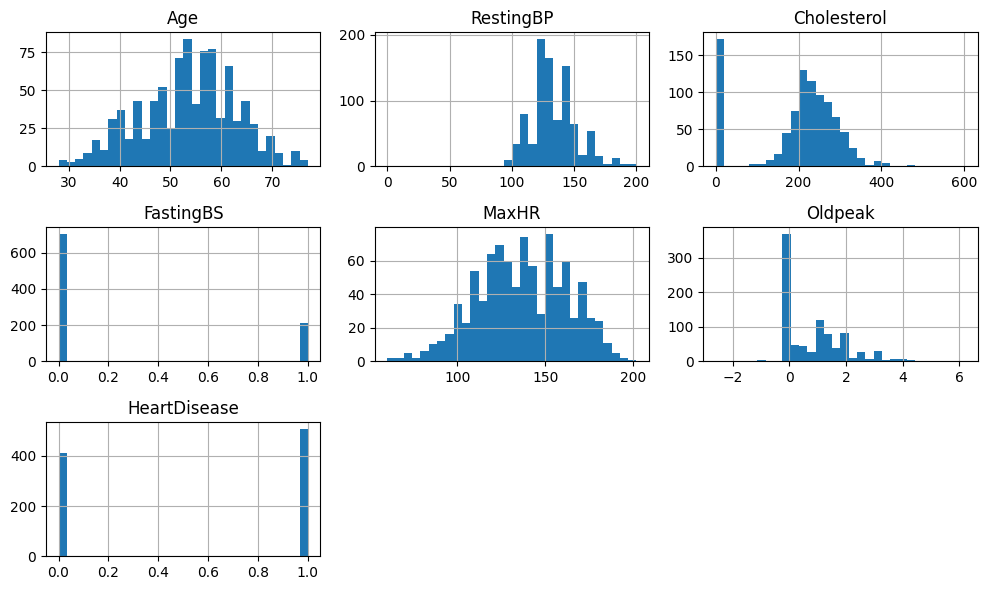

In [10]:
df.hist(bins = 30, figsize=(10,6))
plt.tight_layout()

Text(0.5, 1.0, 'Correlation Matrix')

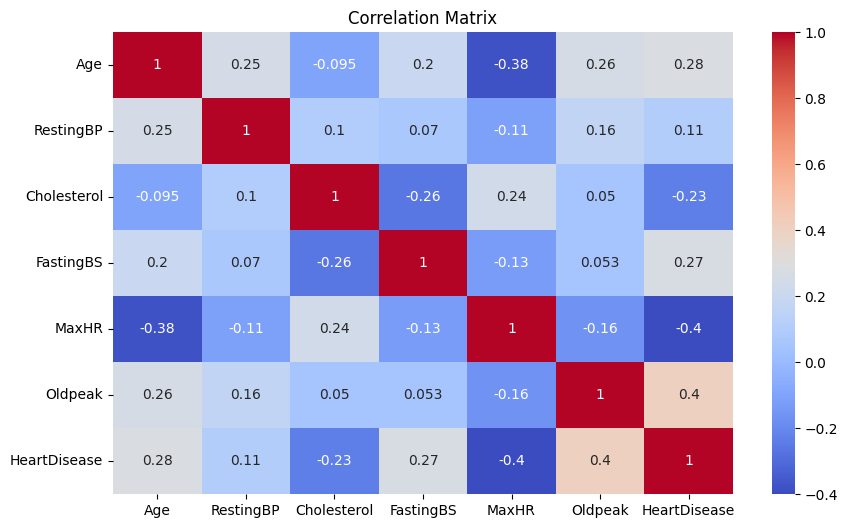

In [11]:
num_df = df.select_dtypes(exclude="object")
df_cor = num_df.corr()

plt.figure(figsize = (10,6))
sns.heatmap(df_cor, annot=True, cmap= 'coolwarm')
plt.title('Correlation Matrix')

#### Data Preprocessing

In [12]:
# Cncode Categorical Data
for col in df.select_dtypes(include = 'object'):
    df[col] = LabelEncoder().fit_transform(df[col])

In [13]:
# Split dataset 
x = df.drop(columns=['HeartDisease'])
y = df['HeartDisease']

x_train, x_test, y_train, y_test = train_test_split(x, y, test_size = 0.2, random_state=42)

In [14]:
# scale to normalize features
scaler = RobustScaler()
x_train = scaler.fit_transform(x_train)
x_test = scaler.transform(x_test)

#### DL Model

In [15]:
model = Sequential([
    Input(shape=(11,)),             # Input layer (11 features)
    Dense(32, activation='relu'),  
    BatchNormalization(),           # Normalize activations
    Dropout(0.2),                   # Prevent overfitting

    Dense(128, activation='relu'),  # Hidden Layer 1
    BatchNormalization(),
    Dropout(0.3),
    
    Dense(64, activation='relu'),   # Hidden Layer 2
    BatchNormalization(),
    Dropout(0.3),

    Dense(32, activation='relu'),   # Hidden Layer 3
    BatchNormalization(),
    Dropout(0.2),

    Dense(1, activation='sigmoid')   # Output Layer (Binary Classification), 'softmax' for multiclassifaction
])


In [16]:
# complite arcitecture
model.compile(optimizer = 'adam', loss='binary_crossentropy', metrics = ['accuracy'])
model.fit(x_train, y_train, epochs=200, batch_size=32, validation_data=(x_test, y_test))

Epoch 1/200
23/23 ━━━━━━━━━━━━━━━━━━━━ 5s 23ms/step - accuracy: 0.5984 - loss: 0.7381 - val_accuracy: 0.7826 - val_loss: 0.6375
Epoch 2/200
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.7296 - loss: 0.5869 - val_accuracy: 0.7935 - val_loss: 0.5893
Epoch 3/200
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.8110 - loss: 0.4391 - val_accuracy: 0.8152 - val_loss: 0.5479
Epoch 4/200
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.7960 - loss: 0.4765 - val_accuracy: 0.8315 - val_loss: 0.5112
Epoch 5/200
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.8155 - loss: 0.4430 - val_accuracy: 0.8370 - val_loss: 0.4751
Epoch 6/200
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.8358 - loss: 0.4166 - val_accuracy: 0.8315 - val_loss: 0.4432
Epoch 7/200
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.8335 - loss: 0.3811 - val_accuracy: 0.8261 - val_loss: 0.4136
Epoch 8/200
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.8395 - loss: 0.3695 - val_accuracy: 0.8152 - 

In [17]:
# Evaluate model
print("Test Accuracy:", model.evaluate(x_test, y_test)[1])

6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.8783 - loss: 0.3545 
Test Accuracy: 0.885869562625885


In [18]:
# Summarize model
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 32)             │           384 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 32)             │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │         4,224 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 64)             │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 32)             │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 46,981 (183.52 KB)

 Trainable params: 15,489 (60.50 KB)

 Non-trainable params: 512 (2.00 KB)

 Optimizer params: 30,980 (121.02 KB)